# 03 · Experiment E3 — does the cost of stale data depend on what the aircraft is doing?

**Question (RQ3, H2).** Constant-velocity reasoning makes stale state look
harmless. Real aircraft turn, climb and accelerate. Notebook 02 showed that
error is a clean function of Age of Information *when pooled*; this notebook
asks whether that function has the same slope in every flight phase.

Phases are derived from the 62 Hz reference trajectory itself (turn rate,
vertical speed, along-track acceleration) rather than from autopilot mode
flags, so the same rule can be applied to any dataset.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import sys, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import os; os.chdir(ROOT)

import numpy as np
import pandas as pd
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 40)

from telemetry_freshness.viz import style as S, figures as F
S.use_paper_style()
print("working dir:", ROOT)

working dir: /path/to/Field_Measurement_of_Age_of_Information


In [2]:
from telemetry_freshness.data.idf_ds import IdfDsDataset
from telemetry_freshness.evaluation.phases import (
    PhaseThresholds, label_phases, attach_phase, phase_summary)
from telemetry_freshness.telemetry.generator import TrajectorySampler, generate_stream
from telemetry_freshness.telemetry.network_model import TelemetryConfig
from telemetry_freshness.surveillance.state_store import SurveillanceStateStore
from telemetry_freshness.surveillance.age_of_information import freshness_errors
from telemetry_freshness.core.rng import make_rng

ds = IdfDsDataset()
LAPS = ds.scenarios()[:12]
TH = PhaseThresholds(turn_rate_deg_s=3.0, vertical_speed_mps=1.0, accel_mps2=0.5)
print("phase thresholds:", TH)

phase thresholds: PhaseThresholds(turn_rate_deg_s=3.0, vertical_speed_mps=1.0, accel_mps2=0.5, smooth_s=1.0)


In [3]:
rows = []
for lap in LAPS:
    traj = label_phases(ds.load_scenario(lap), TH)
    s = TrajectorySampler(traj)
    t_eval = np.arange(s.t_start + 10, s.t_end - 5, 0.2)
    for rate in (5, 2, 1):
        for lat_ms in (0, 250, 500):
            cfg = TelemetryConfig(update_rate_hz=rate, latency_ms=lat_ms)
            store = SurveillanceStateStore()
            store.ingest(generate_stream(s, cfg, make_rng(2026, f"{lap}|{rate}|{lat_ms}")))
            f = freshness_errors(store, s, t_eval)
            f = f[f.tracked]
            f = attach_phase(f, traj)
            f["scenario_id"] = lap; f["update_rate_hz"] = rate; f["latency_ms"] = lat_ms
            rows.append(f)

E3 = pd.concat(rows, ignore_index=True)
E3.to_parquet("results/raw/E3_maneuver_sensitivity.parquet", index=False)
print(f"{len(E3):,} observations")
display(E3.phase.value_counts(normalize=True).round(3).to_frame("share of flight time"))

255,258 observations


,share of flight time
phase,
turn,0.633
climb,0.127
cruise,0.114
descent,0.093
accel,0.034


### Controlling for age

Phases differ in how much time they occupy *and* in the ages they experience.
Comparing raw error across phases would confound the two, so the comparison is
made inside a narrow AoI band.

In [4]:
BAND = (0.9, 1.1)
band = E3[E3.aoi_s.between(*BAND)].copy()
print(f"AoI band {BAND[0]}-{BAND[1]} s   n = {len(band):,}")
summary = phase_summary(band)
display(summary.round(2))
summary.to_csv("results/processed/E3_phase_summary.csv", index=False)

AoI band 0.9-1.1 s   n = 19,326


,phase,n,median,p95,max,amplification_vs_cruise
0,cruise,2243,11.31,15.92,21.90,1.00
1,turn,12162,9.37,17.33,29.42,0.83
2,climb,2505,10.71,19.38,22.25,0.95
3,descent,1767,14.95,24.04,29.08,1.32
4,accel,649,10.54,15.93,19.88,0.93


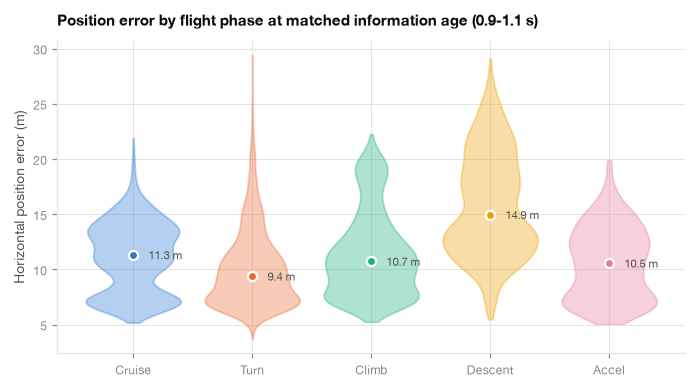

In [5]:
fig, ax = F.fig_error_by_flight_phase(
    band, phase_col="phase", err_col="horiz_error_m",
    title=f"Position error by flight phase at matched information age ({BAND[0]}-{BAND[1]} s)")
S.save(fig, "F1b_error_by_flight_phase"); S.plt.show()

### The naive expectation does not survive contact with the data

The research plan anticipated that a turn would inflate position error. It does
not. At matched age, turning shows the *lowest* median position error of any
phase — because a turning aircraft's chord is shorter than the straight-line
distance a constant-velocity prediction assumes, so the stale position is
actually closer to the truth.

What a turn destroys is the **direction**, and two confounds have to be removed
before that is visible:

1. phases fly at different speeds (descent here is ~50% faster), so raw metres
   are not comparable — normalise error by speed, giving an *effective time lag*;
2. heading error must be reported separately from position error.

In [6]:
band = band.copy()
# Error normalised by true speed: metres of error per metre/second of speed,
# i.e. the effective lag in seconds. This makes phases at different speeds
# directly comparable.
band["effective_lag_s"] = band["horiz_error_m"] / band["truth_speed_mps"].replace(0, np.nan)

cmp = (band.groupby("phase", observed=True)
       .agg(n=("horiz_error_m","size"),
            speed_mps=("truth_speed_mps","median"),
            pos_err_p50=("horiz_error_m","median"),
            pos_err_p95=("horiz_error_m", lambda s: s.quantile(.95)),
            eff_lag_p50=("effective_lag_s","median"),
            hdg_err_p50=("heading_error_deg","median"),
            hdg_err_p95=("heading_error_deg", lambda s: s.quantile(.95)))
       .round(2))
ref = cmp.loc["cruise"] if "cruise" in cmp.index else cmp.iloc[0]
cmp["pos_vs_cruise"] = (cmp.pos_err_p50 / ref.pos_err_p50).round(2)
cmp["hdg_vs_cruise"] = (cmp.hdg_err_p50 / ref.hdg_err_p50).round(2)
display(cmp)
cmp.to_csv("results/processed/E3_phase_summary.csv")

,n,speed_mps,pos_err_p50,pos_err_p95,eff_lag_p50,hdg_err_p50,hdg_err_p95,pos_vs_cruise,hdg_vs_cruise
phase,,,,,,,,,
accel,649,11.15,10.54,15.93,0.96,1.76,8.03,0.93,1.21
climb,2505,11.17,10.71,19.38,0.97,2.24,8.48,0.95,1.54
cruise,2243,11.64,11.31,15.92,0.97,1.45,5.70,1.00,1.00
descent,1767,15.50,14.95,24.04,0.96,1.04,3.20,1.32,0.72
turn,12162,9.82,9.37,17.33,0.96,8.58,31.09,0.83,5.92


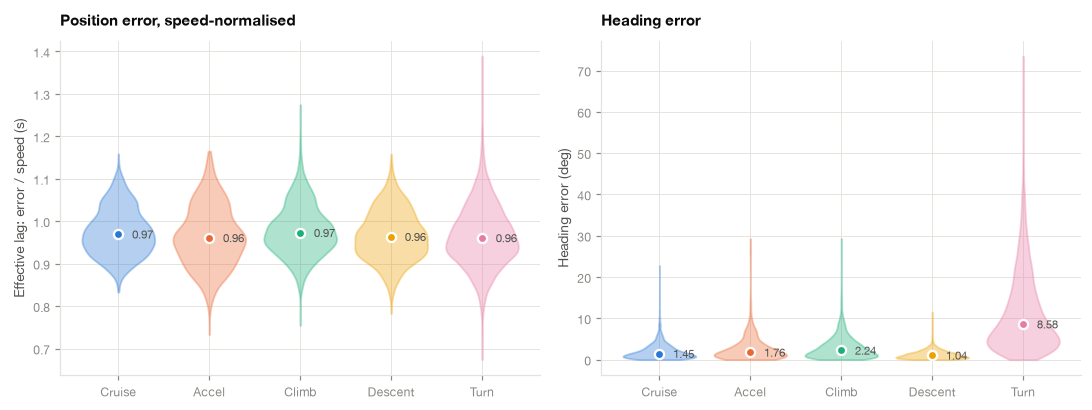

In [7]:
fig, axes = S.plt.subplots(1, 2, figsize=(10.0, 3.8))
phases = [p for p in ("cruise","accel","climb","descent","turn") if p in set(band.phase.dropna())]
colors = S.categorical_colors(len(phases))

for ax, col, lbl, ttl in (
    (axes[0], "effective_lag_s", "Effective lag: error / speed (s)", "Position error, speed-normalised"),
    (axes[1], "heading_error_deg", "Heading error (deg)", "Heading error"),
):
    data = [band.loc[band.phase == p, col].dropna().to_numpy() for p in phases]
    parts = ax.violinplot(data, showextrema=False, widths=0.8)
    for body, c in zip(parts["bodies"], colors):
        body.set_facecolor(c); body.set_alpha(0.35)
        body.set_edgecolor(c); body.set_linewidth(1.2)
    for i, (v, c) in enumerate(zip(data, colors), start=1):
        if not len(v): continue
        m = float(np.median(v))
        ax.plot([i], [m], marker="o", ms=6, color=c, zorder=4,
                markeredgecolor=S.INK["surface"], markeredgewidth=1.5)
        ax.annotate(f"{m:.2f}", (i, m), textcoords="offset points", xytext=(9, 0),
                    fontsize=7.5, color=S.INK["secondary"], va="center")
    ax.set_xticks(range(1, len(phases)+1)); ax.set_xticklabels([p.title() for p in phases])
    ax.set_ylabel(lbl); ax.set_title(ttl)

S.finish(fig, axes); S.save(fig, "F1b_phase_position_vs_heading"); S.plt.show()

Once speed is controlled for, the phases sit within a narrow band on position
error, while heading error separates them sharply. The operational consequence
is that manoeuvring degrades the *predicted track* rather than the current
position — which is why the conflict-detection experiments key on TTC error
(notebook 04) rather than on position error alone.

## Error growth with age, per phase

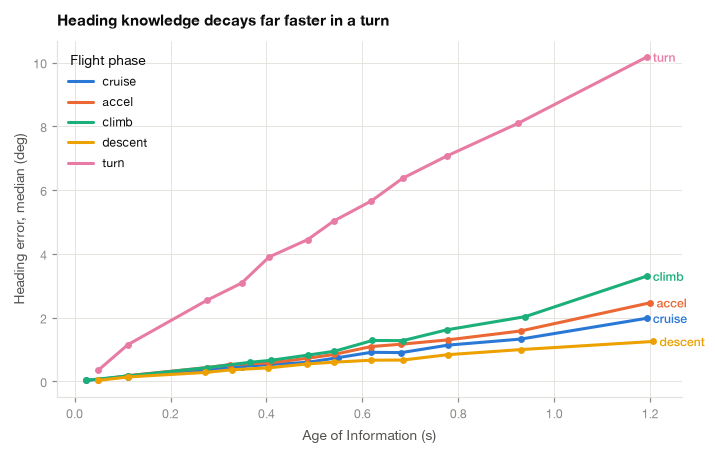

,heading-error growth (deg per second of age)
cruise,1.60
accel,1.98
climb,2.63
descent,1.05
turn,8.62


In [8]:
fig, ax = S.plt.subplots(figsize=(6.6, 4.2))
phases = [p for p in ("cruise","accel","climb","descent","turn") if p in set(E3.phase.dropna())]
colors = S.categorical_colors(len(phases))
slopes = {}
for p, c in zip(phases, colors):
    g = E3[E3.phase == p].dropna(subset=["aoi_s","heading_error_deg"])
    if len(g) < 200: continue
    b = (g.assign(_b=pd.qcut(g.aoi_s, 12, duplicates="drop"))
           .groupby("_b", observed=True)
           .agg(aoi=("aoi_s","median"), err=("heading_error_deg","median")).dropna())
    ax.plot(b.aoi, b.err, color=c, marker="o", ms=3.5, zorder=3)
    S.direct_label(ax, b.aoi.iloc[-1], b.err.iloc[-1], p, c)
    slopes[p] = float(np.polyfit(b.aoi, b.err, 1)[0])
ax.set_xlabel("Age of Information (s)"); ax.set_ylabel("Heading error, median (deg)")
ax.set_title("Heading knowledge decays far faster in a turn")
ax.legend(handles=[S.plt.Line2D([], [], color=c, lw=2, label=p) for p, c in zip(phases, colors)],
          title="Flight phase", loc="upper left")
S.finish(fig, ax); S.save(fig, "S7_heading_error_growth_by_phase"); S.plt.show()

display(pd.Series(slopes, name="heading-error growth (deg per second of age)").round(2).to_frame())

> **Finding (revises H2).** The research plan's hypothesis was that manoeuvring
> amplifies the position error caused by stale data. On these real fixed-wing
> flights it does not: at matched information age, turning produces the
> *smallest* median position error. What manoeuvring destroys is heading
> knowledge, and therefore the extrapolated track. H2 should be restated in
> terms of predicted-track error rather than position error.